<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/1_foundations/dynamics_relativity/make_figures_ch05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Dynamics and Relativity* — `make_figures_ch05.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Dynamics & Relativity — Chapter 5 Figures
Generates all figures for **Chapter 5**

| Figure | Filename | Used in |
|--------|----------|---------|
| Bouncing balls (stacked) | `fig_bouncing_balls.png` | §5.2.1 |
| $\pi$-counting balls + wall | `fig_pi_balls.png` | §5.2.2 |
| Rocket diagram | `fig_rocket.png` | §5.3.1 |
| Rolling hoop | `fig_rolling_hoop.png` | §5.4.5 |
| Physical pendulum (rod) | `fig_phys_pendulum.png` | §5.4.5 |
| Rolling disc on slope | `fig_rolling_disc.png` | §5.4.5 |


## Setup

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import FancyArrowPatch, Arc, Circle, FancyBboxPatch
import os

os.makedirs('figures', exist_ok=True)

# Dark theme palette
DARK_BG = '#1a1a2e'
BLUE    = '#7ec8e3'
YELLOW  = '#f9c74f'
GREEN   = '#90ee90'
RED     = '#e07070'
WHITE   = '#e8e8e8'
DIM     = '#888888'

def base_style(ax, bg=DARK_BG):
    ax.set_facecolor(bg)
    ax.tick_params(colors=DIM, labelsize=9)
    for spine in ax.spines.values():
        spine.set_edgecolor(DIM)
    ax.xaxis.label.set_color(WHITE)
    ax.yaxis.label.set_color(WHITE)

print('Setup complete.')

Setup complete.


## Fig 1 — Bouncing Balls (§5.2.1)

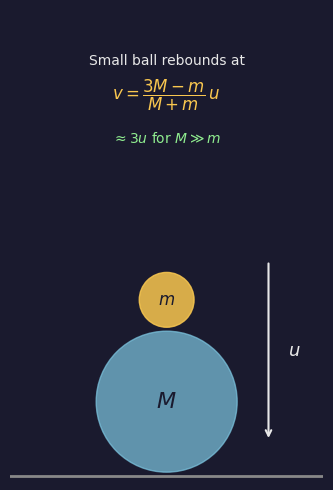

✓ fig_bouncing_balls.png


In [2]:
def fig_bouncing_balls():
    fig, ax = plt.subplots(figsize=(4, 5), facecolor=DARK_BG)
    base_style(ax)
    ax.set_xlim(0, 4); ax.set_ylim(0, 6)
    ax.set_aspect('equal')
    ax.axis('off')

    # Ground
    ax.axhline(0.05, color=DIM, lw=2)

    # Big ball M
    cx, cy_big = 2.0, 1.0
    R_big = 0.9
    big = Circle((cx, cy_big), R_big, color=BLUE, alpha=0.7, zorder=3)
    ax.add_patch(big)
    ax.text(cx, cy_big, r'$M$', ha='center', va='center',
            color=DARK_BG, fontsize=16, fontweight='bold', zorder=4)

    # Small ball m
    R_small = 0.35
    cy_small = cy_big + R_big + R_small + 0.05
    small = Circle((cx, cy_small), R_small, color=YELLOW, alpha=0.85, zorder=3)
    ax.add_patch(small)
    ax.text(cx, cy_small, r'$m$', ha='center', va='center',
            color=DARK_BG, fontsize=12, fontweight='bold', zorder=4)

    # Arrow: falling
    ax.annotate('', xy=(cx + 1.3, 0.5), xytext=(cx + 1.3, 2.8),
                arrowprops=dict(arrowstyle='->', color=WHITE, lw=1.5))
    ax.text(cx + 1.55, 1.65, r'$u$', color=WHITE, fontsize=13, va='center')

    # Result annotation
    ax.text(cx, 5.3, r'Small ball rebounds at', color=WHITE, fontsize=10, ha='center')
    ax.text(cx, 4.85, r'$v = \dfrac{3M-m}{M+m}\,u$', color=YELLOW, fontsize=12, ha='center')
    ax.text(cx, 4.3, r'$\approx 3u$ for $M \gg m$', color=GREEN, fontsize=10, ha='center')

    fig.tight_layout()
    fig.savefig('figures/fig_bouncing_balls.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('✓ fig_bouncing_balls.png')

fig_bouncing_balls()

## Fig 2 — $\pi$ Counting Balls (§5.2.2)

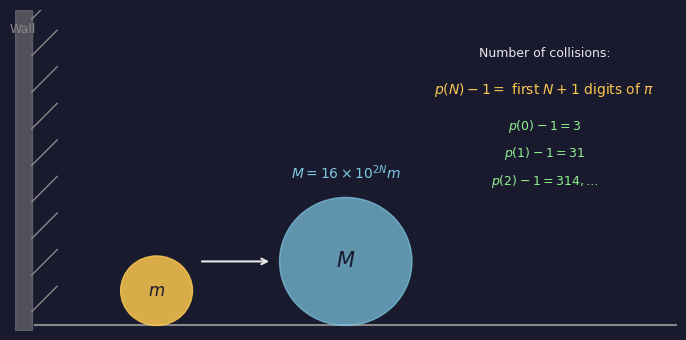

✓ fig_pi_balls.png


In [9]:
def fig_pi_balls():
    fig, ax = plt.subplots(figsize=(7, 3.5), facecolor=DARK_BG)
    base_style(ax)
    ax.set_xlim(0, 7); ax.set_ylim(0, 3.5)
    ax.axis('off')

    # Wall on left
    ax.fill_between([0, 0.18], [0, 0], [3.5, 3.5], color=DIM, alpha=0.5)
    for y in np.arange(0.2, 3.5, 0.4):
        ax.plot([0.18, 0.45], [y, y+0.28], color=DIM, lw=1)
    ax.text(0.09, 3.25, 'Wall', color=DIM, fontsize=9, ha='center')

    # Ground
    ax.axhline(0.05, color=DIM, lw=1.5, xmin=0.03)

    # Light ball m
    R_m = 0.38
    cx_m, cy_m = 1.5, R_m + 0.05
    ball_m = Circle((cx_m, cy_m), R_m, color=YELLOW, alpha=0.85, zorder=3)
    ax.add_patch(ball_m)
    ax.text(cx_m, cy_m, r'$m$', ha='center', va='center',
            color=DARK_BG, fontsize=12, fontweight='bold', zorder=4)

    # Heavy ball M
    R_M = 0.7
    cx_M, cy_M = 3.5, R_M + 0.05
    ball_M = Circle((cx_M, cy_M), R_M, color=BLUE, alpha=0.7, zorder=3)
    ax.add_patch(ball_M)
    ax.text(cx_M, cy_M, r'$M$', ha='center', va='center',
            color=DARK_BG, fontsize=15, fontweight='bold', zorder=4)

    # Arrow: M moves right toward m  ← 방향 수정
    ax.annotate('', xy=(cx_M - R_M - 0.08, cy_M),
                xytext=(cx_M - R_M - 0.85, cy_M),
                arrowprops=dict(arrowstyle='->', color=WHITE, lw=1.5))

    # Mass label above heavy ball
    ax.text(cx_M, cy_M + R_M + 0.2,
            r'$M = 16 \times 10^{2N} m$', color=BLUE, fontsize=10, ha='center')

    # Result text on right side
    ax.text(5.6, 3.1, 'Number of collisions:', color=WHITE, fontsize=9,
            ha='center', va='top')
    ax.text(5.6, 2.72, r'$p(N)-1 =$ first $N+1$ digits of $\pi$',
            color=YELLOW, fontsize=10, ha='center', va='top')
    ax.text(5.6, 2.32, r'$p(0)-1=3$',
            color=GREEN, fontsize=9, ha='center', va='top')
    ax.text(5.6, 2.02, r'$p(1)-1=31$',
            color=GREEN, fontsize=9, ha='center', va='top')
    ax.text(5.6, 1.72, r'$p(2)-1=314, \ldots$',
            color=GREEN, fontsize=9, ha='center', va='top')

    fig.tight_layout()
    fig.savefig('figures/fig_pi_balls.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('✓ fig_pi_balls.png')

fig_pi_balls()

## Fig 3 — Rocket Diagram (§5.3.1)

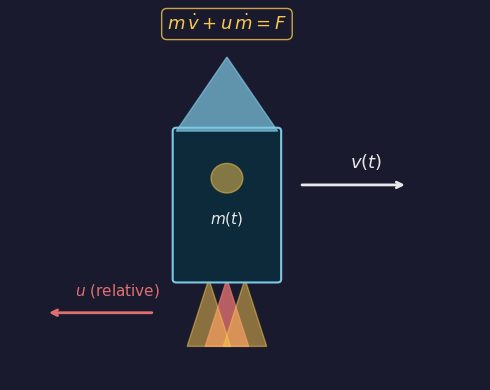

✓ fig_rocket.png


In [4]:
def fig_rocket():
    fig, ax = plt.subplots(figsize=(5, 4), facecolor=DARK_BG)
    base_style(ax)
    ax.set_xlim(-1.5, 5); ax.set_ylim(-0.5, 5)
    ax.axis('off')

    # Rocket body (rectangle + triangle nose)
    body = FancyBboxPatch((0.8, 1.0), 1.4, 2.2,
                           boxstyle='round,pad=0.05',
                           linewidth=1.5, edgecolor=BLUE,
                           facecolor='#0d2a3a', zorder=3)
    ax.add_patch(body)
    # Nose cone
    nose = plt.Polygon([[0.8,3.2],[2.2,3.2],[1.5,4.3]],
                        closed=True, color=BLUE, alpha=0.7, zorder=3)
    ax.add_patch(nose)
    # Window
    win = Circle((1.5, 2.5), 0.22, color=YELLOW, alpha=0.5, zorder=4)
    ax.add_patch(win)

    # Rocket label
    ax.text(1.5, 1.9, r'$m(t)$', color=WHITE, fontsize=11,
            ha='center', va='center', zorder=5)

    # Exhaust plume
    for dx, col, alpha in [(0, RED, 0.8), (-0.25, YELLOW, 0.5), (0.25, YELLOW, 0.5)]:
        plume = plt.Polygon([[1.5+dx, 1.0],[1.2+dx, 0.0],[1.8+dx, 0.0]],
                             closed=True, color=col, alpha=alpha, zorder=2)
        ax.add_patch(plume)

    # Arrow: v (rocket moves right)
    ax.annotate('', xy=(4.0, 2.4), xytext=(2.5, 2.4),
                arrowprops=dict(arrowstyle='->', color=WHITE, lw=2))
    ax.text(3.2, 2.65, r'$v(t)$', color=WHITE, fontsize=13)

    # Arrow: exhaust speed u (relative)
    ax.annotate('', xy=(-1.0, 0.5), xytext=(0.5, 0.5),
                arrowprops=dict(arrowstyle='->', color=RED, lw=2))
    ax.text(-0.6, 0.75, r'$u$ (relative)', color=RED, fontsize=11)

    # Tsiolkovsky eq.
    ax.text(1.5, 4.7,
            r'$m\,\dot{v} + u\,\dot{m} = F$',
            color=YELLOW, fontsize=13, ha='center',
            bbox=dict(boxstyle='round', facecolor='#1a1a2e', edgecolor=YELLOW, alpha=0.8))

    fig.tight_layout()
    fig.savefig('figures/fig_rocket.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('✓ fig_rocket.png')

fig_rocket()

## Fig 4 — Rolling Hoop (§5.4.5)

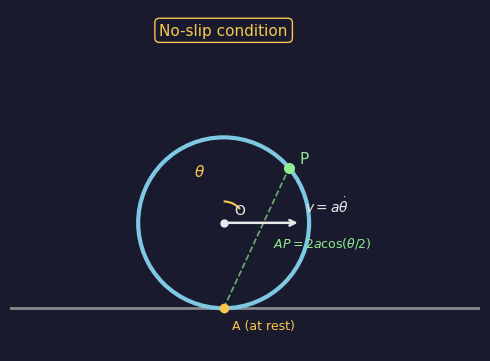

✓ fig_rolling_hoop.png


In [5]:
def fig_rolling_hoop():
    fig, ax = plt.subplots(figsize=(5, 4), facecolor=DARK_BG)
    base_style(ax)
    ax.set_xlim(-0.5, 5); ax.set_ylim(-0.5, 3.5)
    ax.set_aspect('equal')
    ax.axis('off')

    # Ground
    ax.axhline(0, color=DIM, lw=2)

    # Hoop
    cx, cy, a = 2.0, 1.0, 1.0
    hoop = Circle((cx, cy), a, fill=False, edgecolor=BLUE, lw=3, zorder=3)
    ax.add_patch(hoop)

    # Centre dot
    ax.plot(cx, cy, 'o', color=WHITE, ms=5, zorder=5)
    ax.text(cx + 0.12, cy + 0.1, 'O', color=WHITE, fontsize=10)

    # Contact point A
    ax.plot(cx, 0, 'o', color=YELLOW, ms=6, zorder=5)
    ax.text(cx + 0.1, -0.25, 'A (at rest)', color=YELLOW, fontsize=9)

    # Point P at angle theta from top
    theta = np.radians(50)
    px = cx + a*np.sin(theta)
    py = cy + a*np.cos(theta)
    ax.plot(px, py, 'o', color=GREEN, ms=7, zorder=5)
    ax.text(px + 0.12, py + 0.05, 'P', color=GREEN, fontsize=11)

    # Line AP
    ax.plot([cx, px], [0, py], '--', color=GREEN, lw=1.2, alpha=0.7)
    ax.text((cx+px)/2 + 0.2, py/2 - 0.1,
            r'$AP = 2a\cos(\theta/2)$', color=GREEN, fontsize=9)

    # Angle theta at centre
    arc = Arc((cx, cy), 0.5, 0.5, angle=0, theta1=90-np.degrees(theta), theta2=90,
               color=YELLOW, lw=1.5)
    ax.add_patch(arc)
    ax.text(cx - 0.35, cy + 0.55, r'$\theta$', color=YELLOW, fontsize=11)

    # Velocity arrow at CoM
    ax.annotate('', xy=(cx+0.9, cy), xytext=(cx-0.05, cy),
                arrowprops=dict(arrowstyle='->', color=WHITE, lw=1.8))
    ax.text(cx + 0.95, cy + 0.12, r'$v=a\dot{\theta}$', color=WHITE, fontsize=10)

    # No-slip label
    ax.text(2.0, 3.2, 'No-slip condition', color=YELLOW, fontsize=11, ha='center',
            bbox=dict(boxstyle='round', facecolor='#1a1a2e', edgecolor=YELLOW))

    fig.tight_layout()
    fig.savefig('figures/fig_rolling_hoop.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('✓ fig_rolling_hoop.png')

fig_rolling_hoop()

## Fig 5 — Physical Pendulum (§5.4.5)

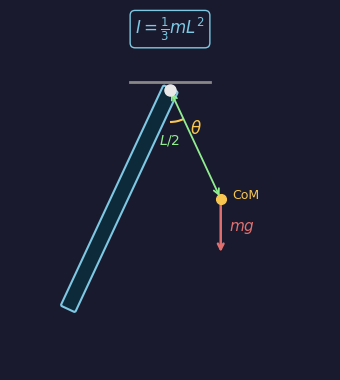

✓ fig_phys_pendulum.png


In [6]:
def fig_phys_pendulum():
    fig, ax = plt.subplots(figsize=(3.5, 5), facecolor=DARK_BG)
    base_style(ax)
    ax.set_xlim(-2, 2); ax.set_ylim(-3.5, 1)
    ax.set_aspect('equal')
    ax.axis('off')

    theta = np.radians(25)
    L = 3.0

    # Pivot
    ax.plot(0, 0, 'o', color=WHITE, ms=8, zorder=5)
    ax.plot([-0.5, 0.5], [0.1, 0.1], color=DIM, lw=2)

    # Rod end point
    x_end = L * np.sin(theta)
    y_end = -L * np.cos(theta)

    # Rod
    rod = patches.FancyBboxPatch(
        (-0.08, -L), 0.16, L,
        boxstyle='round,pad=0.02',
        linewidth=1.5, edgecolor=BLUE,
        facecolor='#0d2a3a', zorder=2
    )
    t = matplotlib.transforms.Affine2D().rotate_around(0, 0, -theta) + ax.transData
    rod.set_transform(t)
    ax.add_patch(rod)

    # CoM dot
    cm_x = (L/2)*np.sin(theta)
    cm_y = -(L/2)*np.cos(theta)
    ax.plot(cm_x, cm_y, 'o', color=YELLOW, ms=7, zorder=5)
    ax.text(cm_x + 0.15, cm_y, 'CoM', color=YELLOW, fontsize=9)

    # L/2 label
    ax.annotate('', xy=(cm_x, cm_y), xytext=(0, 0),
                arrowprops=dict(arrowstyle='<->', color=GREEN, lw=1.3))
    ax.text(cm_x/2 - 0.45, cm_y/2, r'$L/2$', color=GREEN, fontsize=10)

    # Angle theta
    arc = Arc((0,0), 0.8, 0.8, angle=0, theta1=270, theta2=270+np.degrees(theta),
               color=YELLOW, lw=1.5)
    ax.add_patch(arc)
    ax.text(0.25, -0.55, r'$\theta$', color=YELLOW, fontsize=12)

    # Gravity arrow
    ax.annotate('', xy=(cm_x, cm_y - 0.7), xytext=(cm_x, cm_y),
                arrowprops=dict(arrowstyle='->', color=RED, lw=1.8))
    ax.text(cm_x + 0.1, cm_y - 0.4, r'$mg$', color=RED, fontsize=11)

    # Moment of inertia label
    ax.text(0, 0.7, r'$I = \frac{1}{3}mL^2$', color=BLUE, fontsize=12, ha='center',
            bbox=dict(boxstyle='round', facecolor='#1a1a2e', edgecolor=BLUE))

    fig.tight_layout()
    fig.savefig('figures/fig_phys_pendulum.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('✓ fig_phys_pendulum.png')

fig_phys_pendulum()

## Fig 6 — Rolling Disc on Slope (§5.4.5)

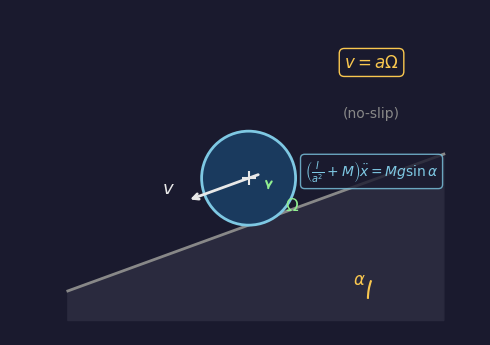

✓ fig_rolling_disc.png


In [7]:
def fig_rolling_disc():
    fig, ax = plt.subplots(figsize=(5, 4), facecolor=DARK_BG)
    base_style(ax)
    ax.set_xlim(-0.5, 6); ax.set_ylim(-0.5, 4)
    ax.set_aspect('equal')
    ax.axis('off')

    alpha = np.radians(20)

    # Slope surface
    x0, x1 = 0.3, 5.5
    y0 = x0*np.tan(alpha)
    y1 = x1*np.tan(alpha)
    ax.fill([0.3, x1, x1, 0.3], [y0, y1, -0.3, -0.3], color='#2a2a3e', zorder=1)
    ax.plot([0.3, x1], [y0, y1], color=DIM, lw=2)

    # Angle alpha
    arc = Arc((x1-0.3, 0), 1.5, 1.5, angle=0,
               theta1=180-np.degrees(alpha), theta2=180,
               color=YELLOW, lw=1.5)
    ax.add_patch(arc)
    ax.text(x1 - 1.25, 0.2, r'$\alpha$', color=YELLOW, fontsize=12)

    # Disc
    a = 0.65
    cx = 2.8
    cy = cx*np.tan(alpha) + a
    disc = Circle((cx, cy), a, fill=True, facecolor='#1a3a5e',
                   edgecolor=BLUE, lw=2, zorder=3)
    ax.add_patch(disc)
    ax.plot(cx, cy, '+', color=WHITE, ms=10, mew=1.5, zorder=5)

    # omega arrow (circular)
    arc_omega = Arc((cx, cy), 0.55, 0.55, angle=0, theta1=30, theta2=330,
                     color=GREEN, lw=2)
    ax.add_patch(arc_omega)
    ax.annotate('', xy=(cx + 0.27, cy - 0.15), xytext=(cx + 0.275, cy - 0.1),
                arrowprops=dict(arrowstyle='->', color=GREEN, lw=1.5))
    ax.text(cx + 0.5, cy - 0.45, r'$\Omega$', color=GREEN, fontsize=12)

    # v arrow (along slope)
    dx = np.cos(alpha)*0.9; dy = np.sin(alpha)*0.9
    ax.annotate('', xy=(cx-dx, cy-dy), xytext=(cx+dx*0.2, cy+dy*0.2),
                arrowprops=dict(arrowstyle='->', color=WHITE, lw=2))
    ax.text(cx - dx - 0.35, cy - dy + 0.1, r'$v$', color=WHITE, fontsize=13)

    # Equation box
    ax.text(4.5, 3.2, r'$v = a\Omega$', color=YELLOW, fontsize=12, ha='center',
            bbox=dict(boxstyle='round', facecolor='#1a1a2e', edgecolor=YELLOW))
    ax.text(4.5, 2.5, r'(no-slip)', color=DIM, fontsize=10, ha='center')

    # Effective mass note
    ax.text(4.5, 1.7,
            r'$\left(\frac{I}{a^2}+M\right)\ddot{x}=Mg\sin\alpha$',
            color=BLUE, fontsize=10, ha='center',
            bbox=dict(boxstyle='round', facecolor='#1a1a2e', edgecolor=BLUE, alpha=0.8))

    fig.tight_layout()
    fig.savefig('figures/fig_rolling_disc.png', dpi=150, bbox_inches='tight', facecolor=DARK_BG)
    plt.show()
    print('✓ fig_rolling_disc.png')

fig_rolling_disc()

## Download all figures as zip

In [8]:
import shutil
from google.colab import files

shutil.make_archive('figures', 'zip', '.', 'figures')
files.download('figures.zip')
print('✓ figures.zip downloaded')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✓ figures.zip downloaded
